# 03 · Filtragem e realce de contraste (CLAHE)

**Ementa 03** · Objetivo: **evidenciar as estruturas de interesse clínico** (vasos, disco, lesões) sem inventar nem destruir informação. Vamos comparar técnicas
**com métricas** — não apenas "ficou bonito" — usando a segmentação manual de vasos do HRF como régua:

1. filtros de suavização (média, gaussiano, mediana, bilateral, *non-local means*) contra dois tipos de ruído;
2. convolução "na mão" e realce de nitidez (*unsharp masking*);
3. equalização global × **CLAHE**; efeito dos parâmetros `clipLimit` e `tileGridSize`;
4. **onde** aplicar o CLAHE (canal verde, luminância L do LAB ou cada canal RGB);
5. correção de iluminação desigual; **ordem** das operações (filtrar antes ou depois do CLAHE?).

> **Nota sobre o "ruído" medido:** o estimador de Immerkaer (`metricas.ruido_sigma`) responde a qualquer variação fina — inclusive à textura real da retina.
> Use-o para *comparar* configurações, não como valor absoluto de ruído.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from retina_pdi import dados, pipeline as P, visualizacao as V

V.configurar_estilo()
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__} | pandas {pd.__version__}")
import time
from skimage.metrics import structural_similarity as ssim
from retina_pdi import metricas as M, qualidade as Q, degradacoes

OpenCV 4.14.0 | NumPy 2.5.3 | pandas 3.0.6


In [2]:
hrf = dados.carregar_hrf(1168)                                   # 45 imagens HRF + máscaras de vasos e FOV
ref = [it for it in hrf if it["meta"].condicao == "normal"][0]   # imagem de referência: saudável, sem ruído apreciável
rgb, fov, vasos = ref["rgb"], ref["fov"], ref["vasos"]
fe = P.erodir_fov(fov, 6)                                        # FOV sem a borda (onde filtros criam artefatos)

# Canal verde, com o preto da moldura substituído pela média local (senão o "preto" vaza para dentro do FOV nos filtros)
verde = P.preencher_fora_do_fov(rgb[..., 1], fov)

disco = P.localizar_disco_optico(rgb, fov)
cy, cx = (int(v) for v in disco.centro)
zoom = (slice(max(cy - 110, 0), cy + 110), slice(max(cx - 110, 0), cx + 110))   # janela ao redor do disco: muitos vasos finos
print(ref["meta"].id, rgb.shape, "· zoom em torno do disco:", (cy, cx))

hrf_01_h (779, 1168, 3) · zoom em torno do disco: (380, 871)


## 1. Filtros de suavização: linear × não linear

Uma retinografia real quase não tem ruído, então **adicionamos ruído de duas naturezas** à imagem "limpa" e medimos o quanto cada filtro consegue devolvê-la:

* **gaussiano** (σ = 15 níveis): ruído do sensor/ganho alto — típico em captura com pouca luz;
* **sal e pimenta** (4 % dos pixels): pixels "mortos" ou saturados — típico de falha de sensor/transmissão.

Medimos: **PSNR/SSIM** contra a imagem limpa e o **contraste dos vasos (Cohen *d*)** — um bom filtro remove ruído *sem borrar os vasos finos*.

In [3]:
rng = np.random.default_rng(0)
limpo = verde
com_gauss = np.clip(limpo + rng.normal(0, 15, limpo.shape), 0, 255).astype(np.uint8)
sorteio = rng.random(limpo.shape)
com_sp = limpo.copy(); com_sp[sorteio < 0.02] = 0; com_sp[sorteio > 0.98] = 255

filtros = {
    "sem filtro":       lambda x: x,
    "média 5×5":        lambda x: cv2.blur(x, (5, 5)),
    "gaussiano σ=1,5":  lambda x: cv2.GaussianBlur(x, (0, 0), 1.5),
    "mediana 5":        lambda x: cv2.medianBlur(x, 5),
    "bilateral":        lambda x: cv2.bilateralFilter(x, 7, 40, 5),
    "non-local means":  lambda x: cv2.fastNlMeansDenoising(x, None, 12, 7, 21),
}

def psnr_mascarado(a, b, m):
    mse = np.mean((a[m].astype(np.float32) - b[m].astype(np.float32)) ** 2)
    return 10 * np.log10(255 ** 2 / mse)

def ssim_mascarado(a, b, m):
    _, mapa = ssim(a, b, full=True, data_range=255)
    return mapa[m].mean()

linhas, resultados = [], {}
for tipo, entrada in [("gaussiano", com_gauss), ("sal e pimenta", com_sp)]:
    for nome, f in filtros.items():
        t0 = time.perf_counter(); s = f(entrada); ms = (time.perf_counter() - t0) * 1e3
        resultados[(tipo, nome)] = s
        linhas.append(dict(ruído=tipo, filtro=nome, PSNR=psnr_mascarado(limpo, s, fe), SSIM=ssim_mascarado(limpo, s, fe),
                           d_vasos=M.cohen_d(s, vasos, fov), ms=ms))
tabela = pd.DataFrame(linhas)
print(f"referência (imagem limpa): d_vasos = {M.cohen_d(limpo, vasos, fov):.2f}")
tabela.pivot(index="filtro", columns="ruído", values=["PSNR", "SSIM", "d_vasos", "ms"]).reindex(list(filtros)).round(2)

referência (imagem limpa): d_vasos = 0.68


PSNR                    SSIM                 d_vasos  \
ruído           gaussiano sal e pimenta gaussiano sal e pimenta gaussiano   
filtro                                                                      
sem filtro          24.61         19.12      0.29          0.29      0.53   
média 5×5           36.09         31.58      0.87          0.74      0.54   
gaussiano σ=1,5     36.60         32.00      0.89          0.77      0.55   
mediana 5           34.99         41.57      0.83          0.96      0.55   
bilateral           35.62         19.58      0.85          0.38      0.56   
non-local means     36.41         19.70      0.88          0.37      0.44   

                                     ms                
ruído           sal e pimenta gaussiano sal e pimenta  
filtro                                                 
sem filtro               0.37      0.00          0.00  
média 5×5                0.53      0.83          0.72  
gaussiano σ=1,5          0.53      0.54          0.31  
mediana 5                0.60      0.91          0.83  
bilateral                0.31      2.24          2.03  
non-local means          0.31    226.25        203.20

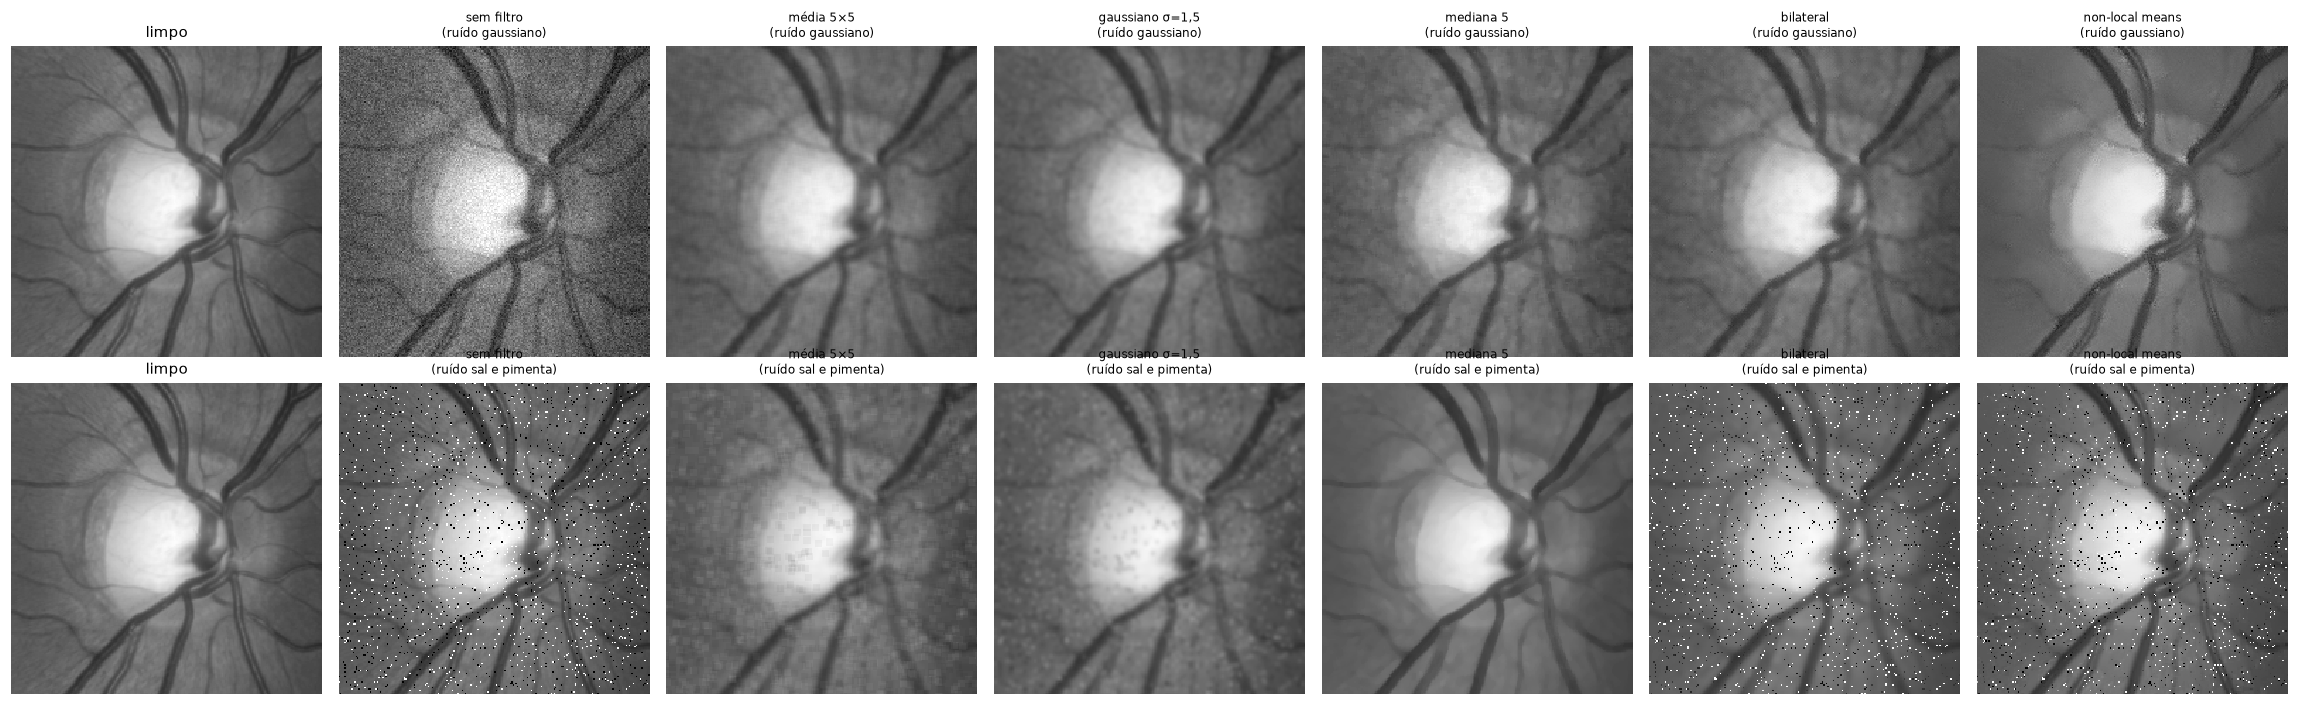

In [4]:
fig, axs = plt.subplots(2, len(filtros) + 1, figsize=(3.0 * (len(filtros) + 1), 6.4))
for i, tipo in enumerate(["gaussiano", "sal e pimenta"]):
    axs[i, 0].imshow(limpo[zoom], cmap="gray", vmin=0, vmax=255); axs[i, 0].set_title("limpo")
    for j, nome in enumerate(filtros):
        axs[i, j + 1].imshow(resultados[(tipo, nome)][zoom], cmap="gray", vmin=0, vmax=255)
        axs[i, j + 1].set_title(f"{nome}\n(ruído {tipo})", fontsize=8)
for a in axs.ravel(): a.axis("off")
fig.tight_layout(); V.salvar_figura(fig, "03_filtros_ruido"); plt.show()

**Leitura dos resultados** (números medidos na tabela acima)

* **Ruído gaussiano:** qualquer suavização recupera boa parte do PSNR (≈ 25 → 35–37 dB). Porém o contraste dos vasos (*d*) só sobe de ≈ 0,53 para ≈ 0,55, ainda longe da imagem limpa (0,68):
  **suavizar reduz o ruído *e* o contraste das estruturas finas** — os vasos têm poucos pixels de largura. O *non-local means* com `h=12` é o mais agressivo (menor *d*) e ~200× mais lento.
* **Sal e pimenta:** a **mediana** é imbatível (≈ 41 dB); os filtros lineares "espalham" cada pixel defeituoso (≈ 31–32 dB) e o **bilateral** e o **NLM**, que tratam o pixel extremo como uma "borda" a preservar, quase não corrigem (≈ 19 dB).
* **Tempo:** no Raspberry Pi (Módulo 3) o NLM pode ser proibitivo. Uma **mediana 3×3 ou um gaussiano leve** costuma ser o melhor custo-benefício antes do realce.

## 2. Convolução "na mão" e realce de nitidez

Todo filtro linear é uma **convolução**: cada pixel de saída é a soma ponderada da vizinhança pelo *kernel*. Implementamos com laços para ver o mecanismo e conferimos contra `cv2.filter2D`:

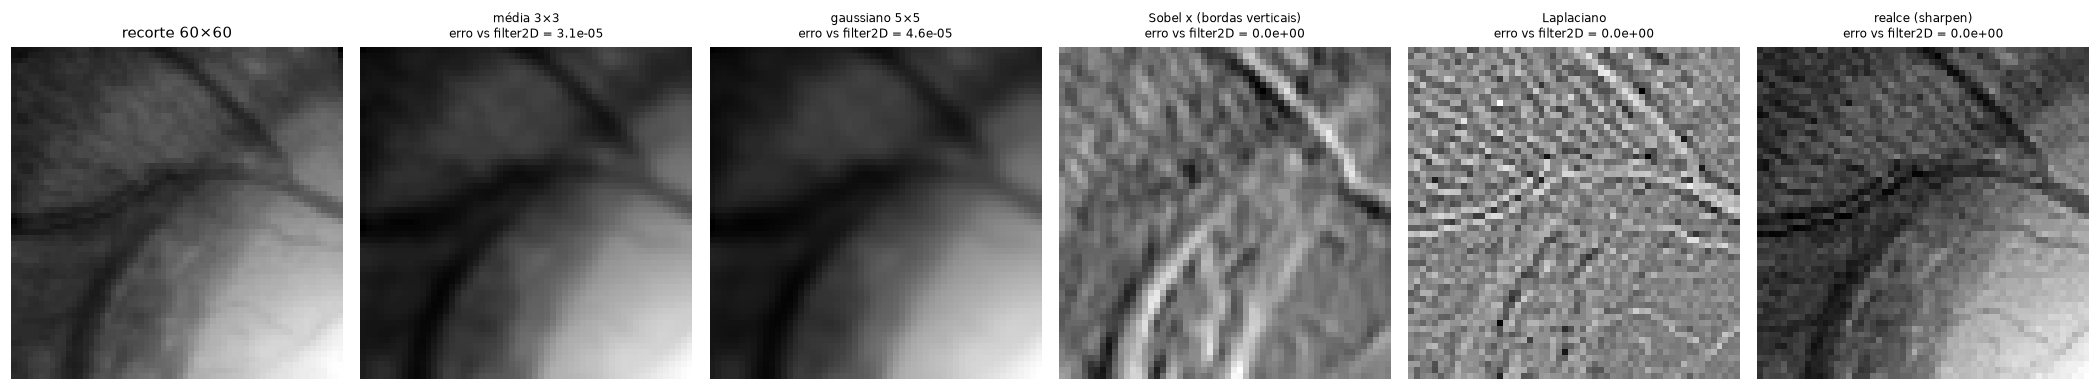

In [5]:
def conv2d_manual(img, kernel):
    """Correlação 2D com laços (sem tratar a borda): somente a parte interior é calculada."""
    kh, kw = kernel.shape
    ph, pw = kh // 2, kw // 2
    saida = np.zeros_like(img, dtype=np.float32)
    for y in range(ph, img.shape[0] - ph):
        for x in range(pw, img.shape[1] - pw):
            saida[y, x] = (img[y - ph:y + ph + 1, x - pw:x + pw + 1] * kernel).sum()
    return saida

pedaco = verde[zoom][40:100, 40:100].astype(np.float32)
kernels = {
    "média 3×3": np.ones((3, 3), np.float32) / 9,
    "gaussiano 5×5": cv2.getGaussianKernel(5, 1.2) @ cv2.getGaussianKernel(5, 1.2).T,
    "Sobel x (bordas verticais)": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32),
    "Laplaciano": np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], np.float32),
    "realce (sharpen)": np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], np.float32),
}
fig, axs = plt.subplots(1, len(kernels) + 1, figsize=(3.2 * (len(kernels) + 1), 3.4))
axs[0].imshow(pedaco, cmap="gray"); axs[0].set_title("recorte 60×60")
for ax, (nome, k) in zip(axs[1:], kernels.items()):
    manual = conv2d_manual(pedaco, k)
    lib = cv2.filter2D(pedaco, -1, k, borderType=cv2.BORDER_REPLICATE)
    erro = np.abs(manual - lib)[3:-3, 3:-3].max()
    ax.imshow(manual[2:-2, 2:-2], cmap="gray"); ax.set_title(f"{nome}\nerro vs filter2D = {erro:.1e}", fontsize=8)
for a in axs: a.axis("off")
fig.tight_layout(); plt.show()

In [6]:
# Separabilidade: um gaussiano 2D grande = dois filtros 1D (muito mais barato). cv2.GaussianBlur já explora isso.
k1d = cv2.getGaussianKernel(61, 10)
k2d = k1d @ k1d.T
g32 = verde.astype(np.float32)
t0 = time.perf_counter(); a = cv2.filter2D(g32, -1, k2d); t2d = (time.perf_counter() - t0) * 1e3
t0 = time.perf_counter(); b = cv2.sepFilter2D(g32, -1, k1d, k1d); t1d = (time.perf_counter() - t0) * 1e3
print(f"kernel 61×61: 2D direto = {t2d:.1f} ms | separável (2×1D) = {t1d:.1f} ms | diferença máx. = {np.abs(a - b).max():.2e}")

kernel 61×61: 2D direto = 11.6 ms | separável (2×1D) = 6.3 ms | diferença máx. = 9.16e-05


### Nitidez: *unsharp masking*
Realça detalhes somando à imagem a diferença entre ela e uma versão borrada: `saída = img + quantidade · (img − gaussiano(img, σ))`.
Aumenta o contraste dos vasos finos, mas **amplifica o ruído** — sempre há um preço.

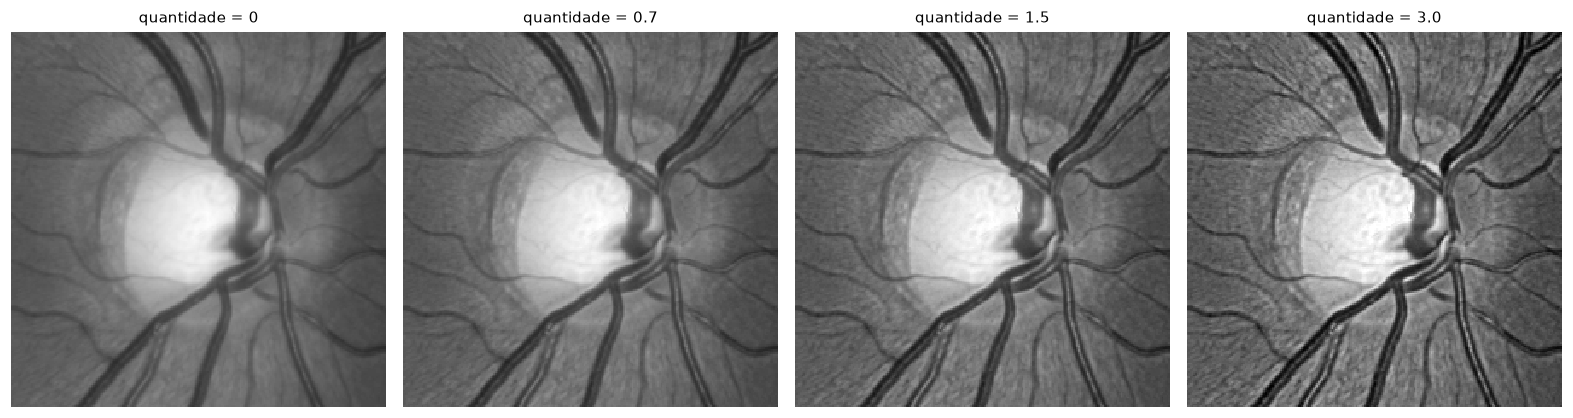

,quantidade,d_vasos,ruído,rms
0,0.0,0.68,0.66,21.71
1,0.7,0.80,1.17,22.36
2,1.5,0.91,1.74,23.32
3,3.0,1.05,2.77,25.62


In [7]:
def unsharp(x, sigma=2.0, quantidade=1.0):
    borrada = cv2.GaussianBlur(x, (0, 0), sigma)
    return cv2.addWeighted(x, 1 + quantidade, borrada, -quantidade, 0)

quantidades = [0, 0.7, 1.5, 3.0]
linhas = []
fig, axs = plt.subplots(1, len(quantidades), figsize=(3.6 * len(quantidades), 3.8))
for ax, q in zip(axs, quantidades):
    s = unsharp(verde, 2.0, q)
    linhas.append(dict(quantidade=q, d_vasos=M.cohen_d(s, vasos, fov), ruído=M.ruido_sigma(s, fe), rms=M.contraste_rms(s, fov)))
    ax.imshow(s[zoom], cmap="gray", vmin=0, vmax=255); ax.set_title(f"quantidade = {q}"); ax.axis("off")
fig.tight_layout(); plt.show()
pd.DataFrame(linhas).round(2)

## 3. Equalização de histograma global × CLAHE

A **equalização global** redistribui os níveis de cinza para usar toda a faixa (histograma ≈ plano). Dois problemas em retinografias:
(1) a **moldura preta** domina o histograma e "puxa" o mapeamento; (2) o mesmo mapeamento vale para a imagem toda, então regiões escuras e claras não são tratadas localmente.

O **CLAHE** (*Contrast Limited Adaptive Histogram Equalization*) divide a imagem em blocos (`tileGridSize`), equaliza cada bloco e **limita** a amplificação (`clipLimit`) para não explodir o ruído; depois interpola entre blocos para evitar emendas.

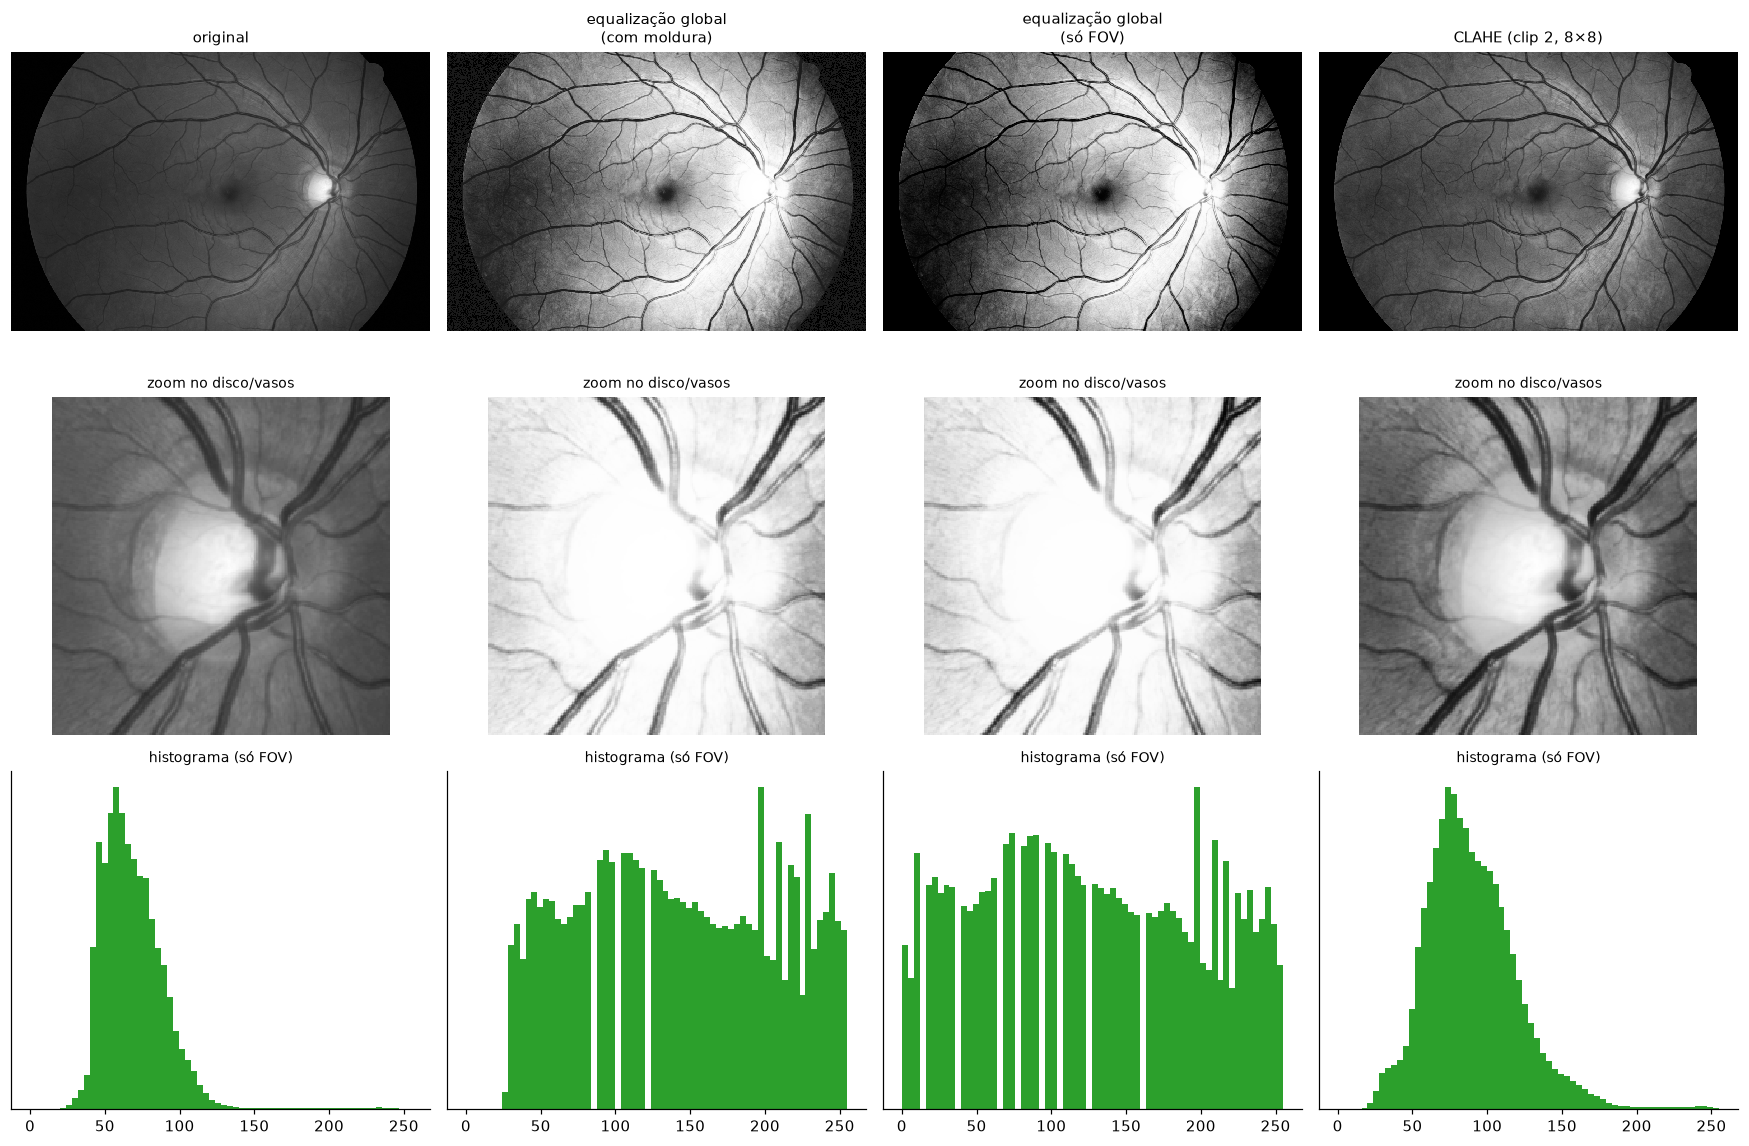

,método,d_vasos,ruído,entropia,rms
0,original,0.68,0.66,6.24,21.71
1,equalização global (com moldura),0.68,2.38,6.11,65.39
2,equalização global (só FOV),0.68,2.67,6.12,73.20
3,"CLAHE (clip 2, 8×8)",1.24,1.67,6.89,30.48


In [8]:
def equalizar_mascarado(canal, mascara):
    """Equalização global calculada só com os pixels do FOV (sem a moldura)."""
    h = np.bincount(canal[mascara], minlength=256).astype(np.float64)
    cdf = np.cumsum(h)
    cdf = (cdf - cdf.min()) / (cdf.max() - cdf.min())
    saida = (255 * cdf).astype(np.uint8)[canal]
    saida[~mascara] = 0
    return saida

verde_bruto = rgb[..., 1]                                # com moldura preta de verdade
candidatos = {
    "original": verde_bruto,
    "equalização global\n(com moldura)": cv2.equalizeHist(verde_bruto),
    "equalização global\n(só FOV)": equalizar_mascarado(verde_bruto, fov),
    "CLAHE (clip 2, 8×8)": np.where(fov, P.clahe(verde, 2.0, (8, 8)), 0).astype(np.uint8),
}
fig, axs = plt.subplots(3, 4, figsize=(16, 10.5))
for j, (nome, im) in enumerate(candidatos.items()):
    axs[0, j].imshow(im, cmap="gray", vmin=0, vmax=255); axs[0, j].set_title(nome)
    axs[1, j].imshow(im[zoom], cmap="gray", vmin=0, vmax=255); axs[1, j].set_title("zoom no disco/vasos", fontsize=9)
    axs[2, j].hist(im[fov].ravel(), bins=64, range=(0, 255), color="tab:green"); axs[2, j].set_yticks([]); axs[2, j].set_title("histograma (só FOV)", fontsize=9)
    axs[0, j].axis("off"); axs[1, j].axis("off")
fig.tight_layout(); V.salvar_figura(fig, "03_equalizacao_vs_clahe"); plt.show()

linhas = [dict(método=n.replace("\n", " "), d_vasos=M.cohen_d(im, vasos, fov), ruído=M.ruido_sigma(im, fe), entropia=M.entropia(im, fov), rms=M.contraste_rms(im, fov))
          for n, im in candidatos.items()]
pd.DataFrame(linhas).round(2)

A equalização global **triplica o contraste RMS**, mas o contraste dos vasos (*d*) **não muda** (0,68 → 0,68): ela estica todos os níveis de uma vez — inclusive as grandes variações de iluminação — sem separar vaso de fundo *localmente*.
O CLAHE, por agir bloco a bloco, eleva o *d* dos vasos de 0,68 para ≈ 1,2 (+80 %) com muito menos aumento de RMS. (Note também o histograma "achatado" da equalização e o histograma mais suave do CLAHE.)
> **Cuidado (borda do FOV):** o CLAHE trabalha por blocos; se os blocos de borda incluem a moldura preta, a estatística fica distorcida. Por isso, aqui e no pipeline, preenchemos o preto com a média local *antes* (`preencher_fora_do_fov`) e o recolocamos depois.

## 4. Parâmetros do CLAHE: `clipLimit` × `tileGridSize`

Varremos 6 valores de `clipLimit` × 5 grades em **9 imagens HRF** (3 saudáveis, 3 RD, 3 glaucoma) e medimos o contraste dos vasos (*d*), o "ruído/textura" e o contraste RMS.
*(Leva alguns segundos.)*

In [9]:
import itertools
selecao = [it for c in ("normal", "rd", "glaucoma") for it in [x for x in hrf if x["meta"].condicao == c][:3]]
clips = [1, 2, 3, 4, 6, 10]
grades = [(2, 2), (4, 4), (8, 8), (16, 16), (32, 32)]

linhas = []
for it in selecao:
    f_, v_ = it["fov"], it["vasos"]; fe_ = P.erodir_fov(f_, 6)
    g0 = P.preencher_fora_do_fov(it["rgb"][..., 1], f_)
    linhas.append(dict(clip_limit=0, grade="original", d=M.cohen_d(g0, v_, f_), ruido=M.ruido_sigma(g0, fe_), rms=M.contraste_rms(g0, f_)))
    for c, gr in itertools.product(clips, grades):
        out = P.clahe(g0, c, gr); out[~f_] = 0
        linhas.append(dict(clip_limit=c, grade=f"{gr[0]}×{gr[1]}", d=M.cohen_d(out, v_, f_), ruido=M.ruido_sigma(out, fe_), rms=M.contraste_rms(out, f_)))
grid = pd.DataFrame(linhas)
base = grid[grid["clip_limit"] == 0][["d", "ruido", "rms"]].mean()
medias = grid[grid["clip_limit"] > 0].groupby(["clip_limit", "grade"]).mean(numeric_only=True).reset_index()
ordem_grade = [f"{a}×{b}" for a, b in grades]
print("original (média das 9 imagens):", base.round(2).to_dict())

original (média das 9 imagens): {'d': 0.81, 'ruido': 0.62, 'rms': 16.68}


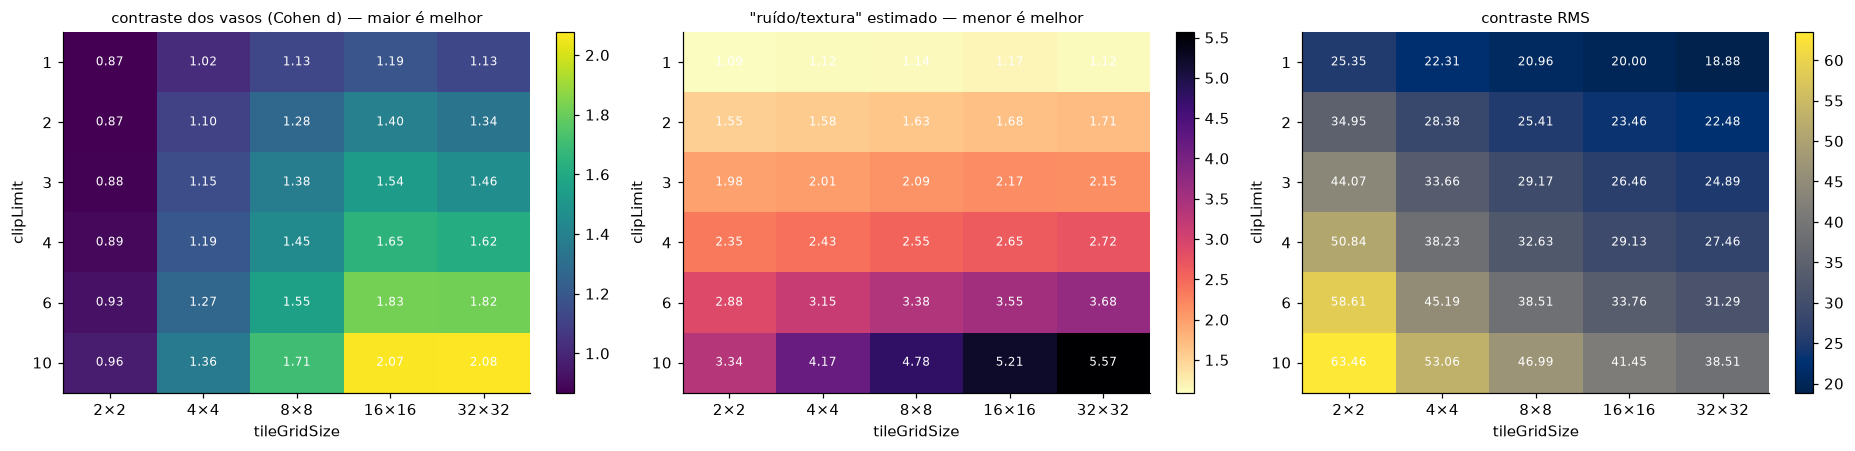

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, (col, titulo, cmap) in zip(axs, [("d", "contraste dos vasos (Cohen d) — maior é melhor", "viridis"),
                                        ("ruido", "\"ruído/textura\" estimado — menor é melhor", "magma_r"),
                                        ("rms", "contraste RMS", "cividis")]):
    piv = medias.pivot(index="clip_limit", columns="grade", values=col)[ordem_grade]
    im = ax.imshow(piv.values, cmap=cmap, aspect="auto")
    ax.set_xticks(range(len(ordem_grade)), ordem_grade); ax.set_yticks(range(len(clips)), clips)
    ax.set_xlabel("tileGridSize"); ax.set_ylabel("clipLimit"); ax.set_title(titulo, fontsize=10)
    for (i, j), v in np.ndenumerate(piv.values):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white", fontsize=8)
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout(); V.salvar_figura(fig, "03_clahe_grid"); plt.show()

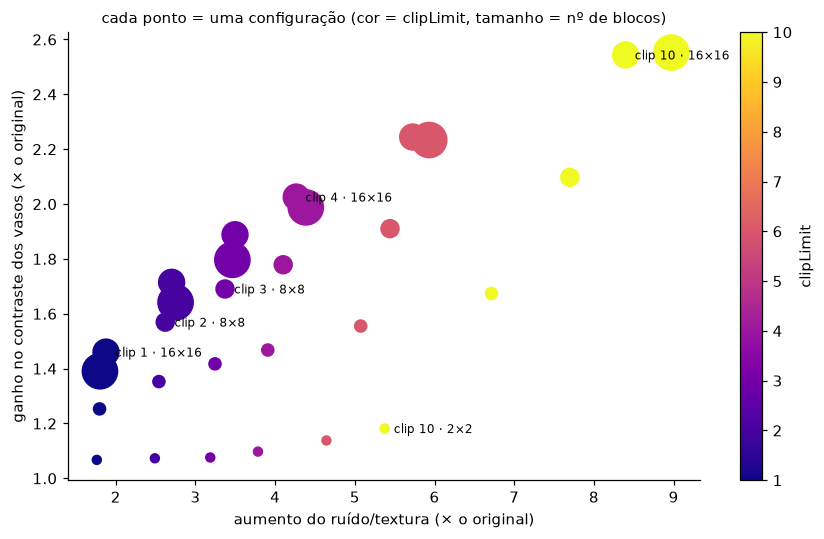

In [11]:
# Trade-off: ganho de contraste dos vasos × aumento do ruído (relativos ao original)
medias["ganho_d"] = medias.d / base.d
medias["aumento_ruido"] = medias.ruido / base.ruido
fig, ax = plt.subplots(figsize=(8, 5))
sc = ax.scatter(medias.aumento_ruido, medias.ganho_d, c=medias.clip_limit, cmap="plasma", s=30 + 4 * np.log2(medias.grade.str.split("×").str[0].astype(int)) ** 3)
for _, r in medias.iterrows():
    if (r.clip_limit, r.grade) in [(1, "16×16"), (2, "8×8"), (3, "8×8"), (4, "16×16"), (10, "2×2"), (10, "16×16")]:
        ax.annotate(f"clip {r.clip_limit:g} · {r.grade}", (r.aumento_ruido, r.ganho_d), textcoords="offset points", xytext=(6, -3), fontsize=8)
ax.set_xlabel("aumento do ruído/textura (× o original)"); ax.set_ylabel("ganho no contraste dos vasos (× o original)")
ax.set_title("cada ponto = uma configuração (cor = clipLimit, tamanho = nº de blocos)"); fig.colorbar(sc, label="clipLimit")
fig.tight_layout(); plt.show()

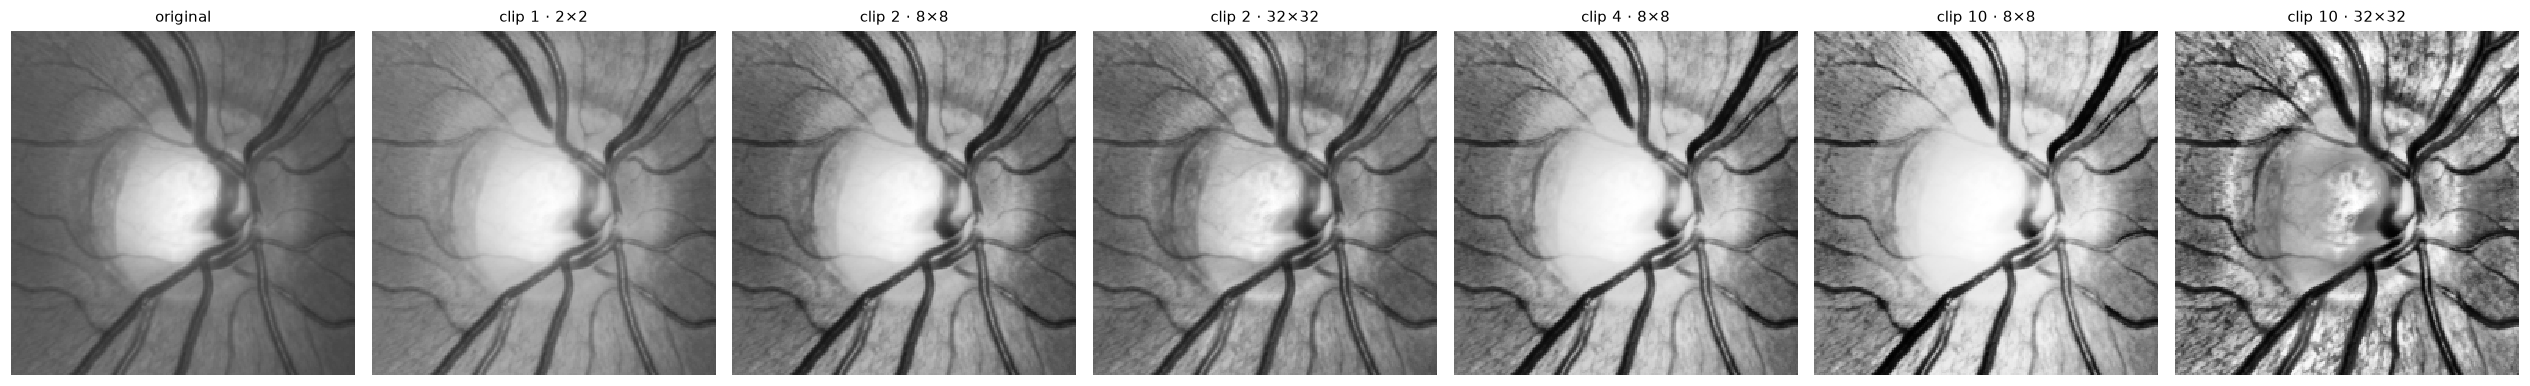

In [12]:
# Como isso aparece na imagem? Seis configurações no mesmo recorte
configs = [(1, (2, 2)), (2, (8, 8)), (2, (32, 32)), (4, (8, 8)), (10, (8, 8)), (10, (32, 32))]
fig, axs = plt.subplots(1, len(configs) + 1, figsize=(3.3 * (len(configs) + 1), 3.6))
axs[0].imshow(verde[zoom], cmap="gray", vmin=0, vmax=255); axs[0].set_title("original")
for ax, (c, gr) in zip(axs[1:], configs):
    ax.imshow(P.clahe(verde, c, gr)[zoom], cmap="gray", vmin=0, vmax=255); ax.set_title(f"clip {c} · {gr[0]}×{gr[1]}")
for a in axs: a.axis("off")
fig.tight_layout(); plt.show()

**Como escolher.** Grade pequena (2×2) mal muda o contraste local; grade grande (16–32) realça vasos finos mas amplifica textura/ruído. `clipLimit` alto multiplica ambos.
O par **clip ≈ 2 com grade 8×8** é o ponto de partida clássico (**note que o padrão da OpenCV é `clipLimit=40`, agressivo demais** para retina). A escolha final deve ser guiada
pela **tarefa-alvo**: Dice da segmentação de vasos (notebook 04) e, no fim, o desempenho dos modelos de RD/Glaucoma/DMRI (Módulo 4) — o melhor CLAHE é o que melhora *essa* métrica, não o que "parece melhor".

## 5. Onde aplicar o CLAHE: verde, L (LAB) ou cada canal RGB?

* **Canal verde** → imagem em tons de cinza; ótimo para vasos, descarta a cor.
* **L do LAB** → realça a luminância e **preserva a cromaticidade** (a*, b*): a imagem continua colorida e "natural". É a escolha padrão do pipeline para a entrada dos modelos.
* **CLAHE em cada canal RGB** → cada canal é esticado de um jeito → **deslocamento de cor** (rios de cor falsos). Medimos a mudança de cromaticidade (Δa*, Δb*) no FOV:

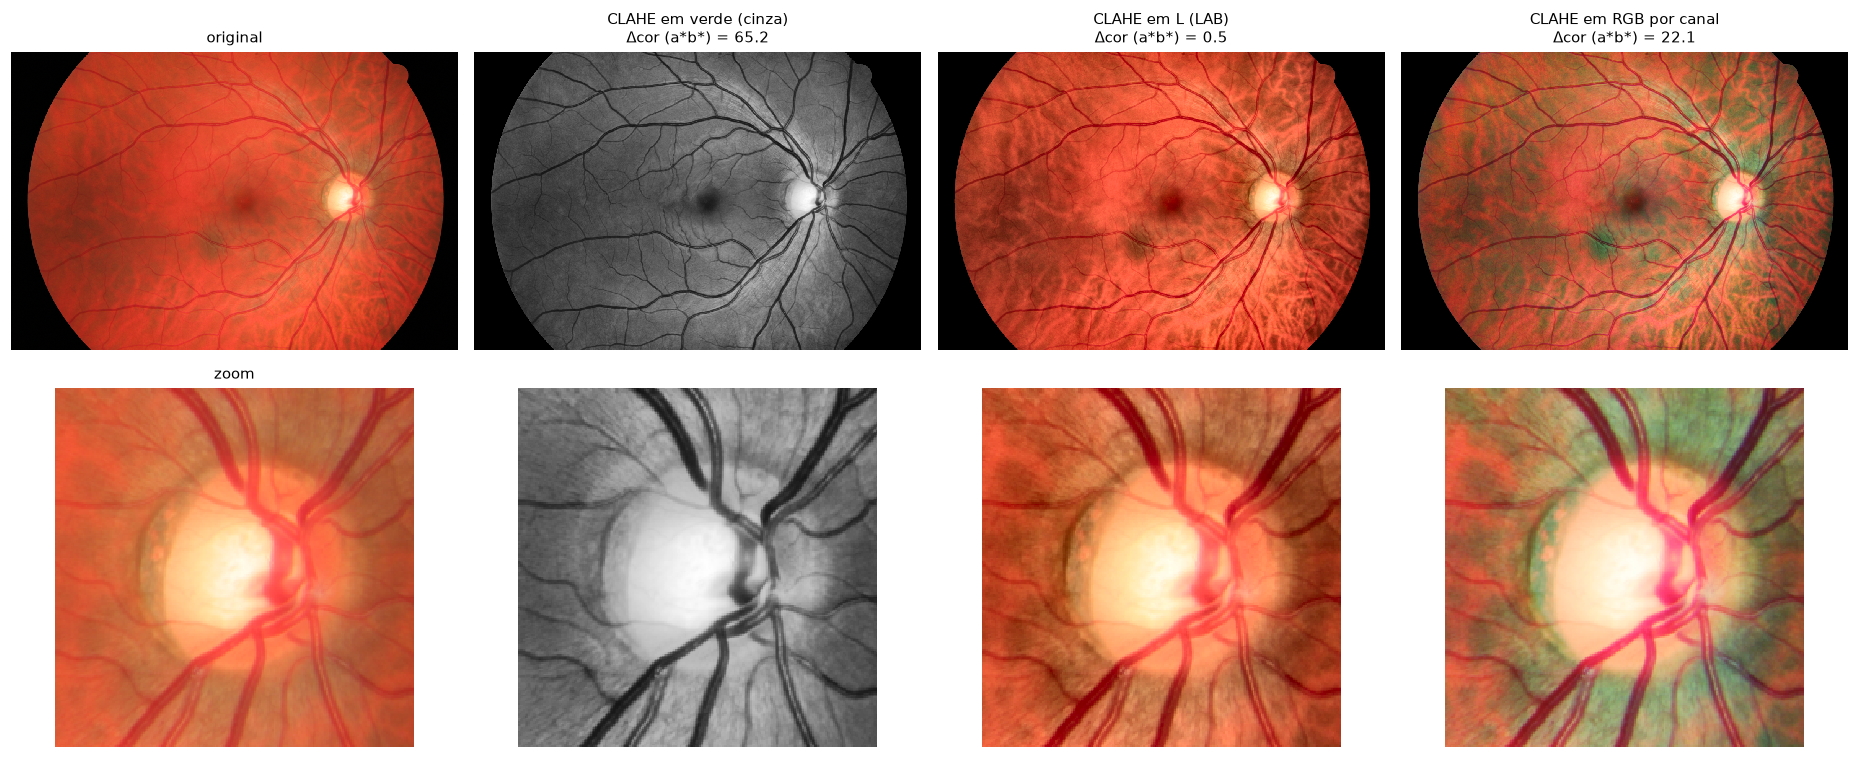

In [13]:
def clahe_em(rgb_, modo, f_, clip=2.0, grade=(8, 8)):
    base_ = np.stack([P.preencher_fora_do_fov(rgb_[..., c], f_) for c in range(3)], -1)       # sem "vazamento" de preto
    if modo == "L (LAB)":
        out = P.clahe_lab(base_, clip, grade)
    elif modo == "RGB por canal":
        out = np.stack([P.clahe(base_[..., c], clip, grade) for c in range(3)], -1)
    else:  # verde
        g_ = P.clahe(base_[..., 1], clip, grade); out = np.stack([g_] * 3, -1)
    out[~f_] = 0
    return out

def deslocamento_de_cor(a, b, f_):
    la, lb = cv2.cvtColor(a, cv2.COLOR_RGB2LAB).astype(np.float32), cv2.cvtColor(b, cv2.COLOR_RGB2LAB).astype(np.float32)
    return float(np.hypot(la[..., 1] - lb[..., 1], la[..., 2] - lb[..., 2])[f_].mean())

modos = ["verde (cinza)", "L (LAB)", "RGB por canal"]
saidas = {m_: clahe_em(rgb, m_ if m_ != "verde (cinza)" else "verde", fov) for m_ in modos}
fig, axs = plt.subplots(2, 4, figsize=(17, 7))
axs[0, 0].imshow(rgb); axs[0, 0].set_title("original"); axs[1, 0].imshow(rgb[zoom]); axs[1, 0].set_title("zoom")
for j, m_ in enumerate(modos, start=1):
    axs[0, j].imshow(saidas[m_]); axs[1, j].imshow(saidas[m_][zoom])
    axs[0, j].set_title(f"CLAHE em {m_}\nΔcor (a*b*) = {deslocamento_de_cor(rgb, saidas[m_], fov):.1f}", fontsize=10)
for a in axs.ravel(): a.axis("off")
fig.tight_layout(); V.salvar_figura(fig, "03_onde_aplicar_clahe"); plt.show()

O CLAHE em **L** mantém a cor original (Δ ≈ 0,5 nível de a\*b\*); o **RGB por canal** desloca a cor de forma visível (manchas esverdeadas, Δ ≈ 22) — evite-o para imagens coloridas que vão para a IA. O **verde** vira uma imagem de 1 canal (por isso Δ alto: não há mais cor) e é suficiente quando o objetivo são só os vasos.

## 6. Iluminação desigual e o efeito de borda

Captura com sombra ou vinheta deixa um **gradiente lento de brilho**. Podemos estimá-lo com um gaussiano muito largo (o "fundo") e subtraí-lo: `canal − fundo + média`.
Detalhe crucial: o gaussiano deve ser **mascarado** (convolução normalizada), senão a moldura preta escurece o fundo estimado perto da borda e cria um **halo** falso.

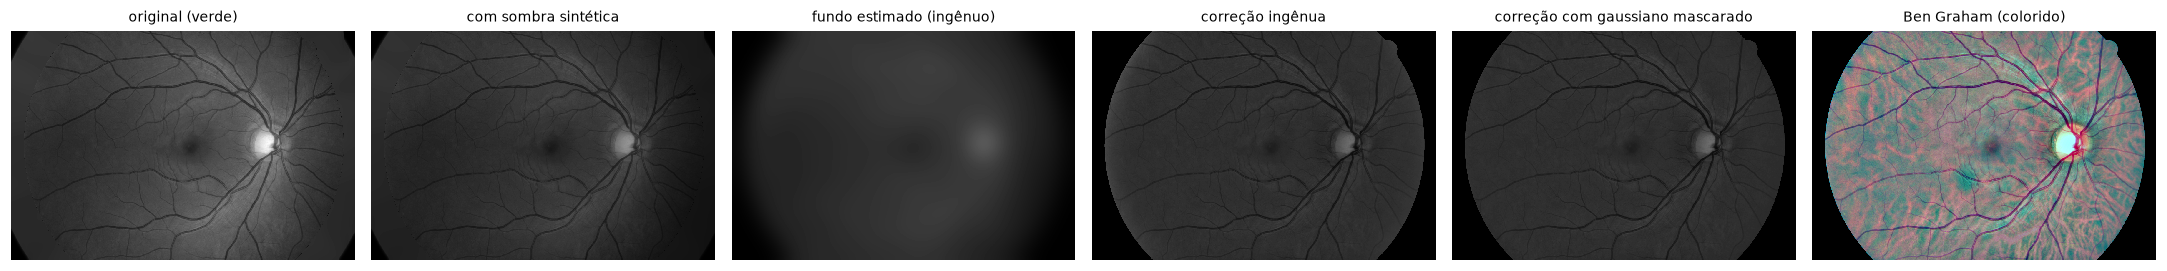

,versão,desigualdade,borda_sobre_interior,invariância_à_sombra
0,original,0.199,0.655,NaN
1,com sombra,0.153,0.672,NaN
2,correção ingênua,0.026,1.245,0.984
3,correção mascarada,0.010,0.968,0.990


In [14]:
# Degradação sintética conhecida: aplicamos uma sombra em rampa (nível 0,7) à imagem HRF e tentamos recuperá-la.
sombra = degradacoes.iluminacao_desigual(rgb, 0.7, angulo=25)
g_orig = P.preencher_fora_do_fov(rgb[..., 1], fov)
g_d = P.preencher_fora_do_fov(sombra[..., 1], fov)
sigma = 0.05 * min(g_d.shape)

def corrigir_ingenua(canal, f_):
    """canal − gaussiano(canal) + média, com o preto da moldura ENTRANDO na média (erro clássico)."""
    fundo = cv2.GaussianBlur(np.where(f_, canal, 0).astype(np.float32), (0, 0), sigma)
    out = np.clip(canal.astype(np.float32) - fundo + canal[f_].mean(), 0, 255).astype(np.uint8)
    out[~f_] = 0
    return out, fundo

corr_ingenua, fundo_ingenuo = corrigir_ingenua(g_d, fov)
corr_certa = P.corrigir_iluminacao(g_d, fov, 0.05)                                                   # gaussiano mascarado
ben = P.realce_ben_graham(sombra, fov)

# Invariância: a MESMA correção aplicada à imagem original (sem sombra) deve dar o mesmo resultado
ref_ingenua, _ = corrigir_ingenua(g_orig, fov)
ref_certa = P.corrigir_iluminacao(g_orig, fov, 0.05)

def desigualdade(canal, f_):
    fundo = P.gaussiano_mascarado(canal, f_, 0.12 * min(canal.shape)); e = P.erodir_fov(f_, 6)
    return float(fundo[e].std() / fundo[e].mean())

def razao_borda_interior(canal, f_):
    """Brilho médio da faixa de 12 px junto à borda do FOV ÷ brilho médio do interior (ideal ≈ 1)."""
    interior = P.erodir_fov(f_, 40); borda = P.erodir_fov(f_, 4) & ~P.erodir_fov(f_, 16)
    return float(canal[borda].mean() / canal[interior].mean())

def correlacao(a, b, f_):
    e = P.erodir_fov(f_, 6)
    return float(np.corrcoef(a[e].ravel().astype(np.float32), b[e].ravel().astype(np.float32))[0, 1])

paineis = [("original (verde)", g_orig), ("com sombra sintética", g_d), ("fundo estimado (ingênuo)", np.clip(fundo_ingenuo, 0, 255).astype(np.uint8)),
           ("correção ingênua", corr_ingenua), ("correção com gaussiano mascarado", corr_certa), ("Ben Graham (colorido)", ben)]
fig, axs = plt.subplots(1, len(paineis), figsize=(3.3 * len(paineis), 3.7))
for ax, (t_, im) in zip(axs, paineis):
    ax.imshow(im, cmap="gray" if im.ndim == 2 else None, vmin=0, vmax=255); ax.set_title(t_, fontsize=9); ax.axis("off")
fig.tight_layout(); V.salvar_figura(fig, "03_iluminacao_correcao"); plt.show()

tabela_il = pd.DataFrame([
    dict(versão="original", desigualdade=desigualdade(g_orig, fov), borda_sobre_interior=razao_borda_interior(g_orig, fov), invariância_à_sombra=np.nan),
    dict(versão="com sombra", desigualdade=desigualdade(g_d, fov), borda_sobre_interior=razao_borda_interior(g_d, fov), invariância_à_sombra=np.nan),
    dict(versão="correção ingênua", desigualdade=desigualdade(corr_ingenua, fov), borda_sobre_interior=razao_borda_interior(corr_ingenua, fov), invariância_à_sombra=correlacao(ref_ingenua, corr_ingenua, fov)),
    dict(versão="correção mascarada", desigualdade=desigualdade(corr_certa, fov), borda_sobre_interior=razao_borda_interior(corr_certa, fov), invariância_à_sombra=correlacao(ref_certa, corr_certa, fov)),
]).round(3)
tabela_il

Como ler a tabela:

* **desigualdade** (variação relativa da iluminação de fundo): cai para ≈ 0,01 nas duas correções — o gradiente lento de iluminação foi removido.
* **invariância à sombra** = correlação entre a correção da imagem *com* sombra e a correção da imagem *original*. Perto de 1 significa que, depois da correção, a sombra deixou de importar. Note que **não** comparamos com a original bruta: a correção também achata o gradiente natural da retina, então ela nunca voltará a ser idêntica a ela.
* **borda / interior**: brilho da faixa junto à borda do FOV dividido pelo do interior (ideal ≈ 1). O gaussiano **ingênuo** mistura o preto da moldura, subestima o fundo perto da borda e deixa um **halo claro** (razão > 1); o **mascarado** (convolução normalizada) fica ≈ 1.

O realce de **Ben Graham** (`4·(I − gaussiana(I)) + 128`, popular em competições de retinopatia diabética) faz algo parecido em cada canal RGB e acentua vasos e lesões,
mas muda bastante a aparência; se usado, deve ser **idêntico no treino e na inferência** (notebook 06).

## 7. Ordem das operações: filtrar antes ou depois do CLAHE?

O CLAHE **amplifica** diferenças locais — inclusive ruído. Testamos as duas ordens sobre uma imagem com ruído gaussiano moderado (σ = 10) e comparamos com o CLAHE da imagem limpa (o "ideal"):

In [15]:
rng = np.random.default_rng(1)
ruidosa = np.clip(limpo + rng.normal(0, 10, limpo.shape), 0, 255).astype(np.uint8)
clahe_ = lambda x: np.where(fov, P.clahe(x, 2.0, (8, 8)), 0).astype(np.uint8)
alvo = clahe_(limpo)                                                       # "resultado ideal"

suaviza = {"mediana 3": lambda x: cv2.medianBlur(x, 3), "gaussiano σ=1": lambda x: cv2.GaussianBlur(x, (0, 0), 1.0),
           "bilateral": lambda x: cv2.bilateralFilter(x, 7, 30, 5)}
receitas = {"só CLAHE": clahe_(ruidosa)}
for n, f in suaviza.items():
    receitas[f"{n} → CLAHE"] = clahe_(f(ruidosa))
    receitas[f"CLAHE → {n}"] = f(clahe_(ruidosa))

linhas = [dict(receita=n, SSIM_vs_ideal=ssim_mascarado(alvo, im, fe), PSNR_vs_ideal=psnr_mascarado(alvo, im, fe), d_vasos=M.cohen_d(im, vasos, fov)) for n, im in receitas.items()]
tab_ordem = pd.DataFrame(linhas).round(3).sort_values("SSIM_vs_ideal", ascending=False)
tab_ordem

,receita,SSIM_vs_ideal,PSNR_vs_ideal,d_vasos
5,bilateral → CLAHE,0.723,30.423000,1.099
4,CLAHE → gaussiano σ=1,0.699,26.632000,1.270
3,gaussiano σ=1 → CLAHE,0.692,29.886999,1.163
2,CLAHE → mediana 3,0.556,25.216000,1.268
1,mediana 3 → CLAHE,0.555,27.214001,1.166
6,CLAHE → bilateral,0.492,24.486000,1.198
0,só CLAHE,0.258,19.969999,1.015


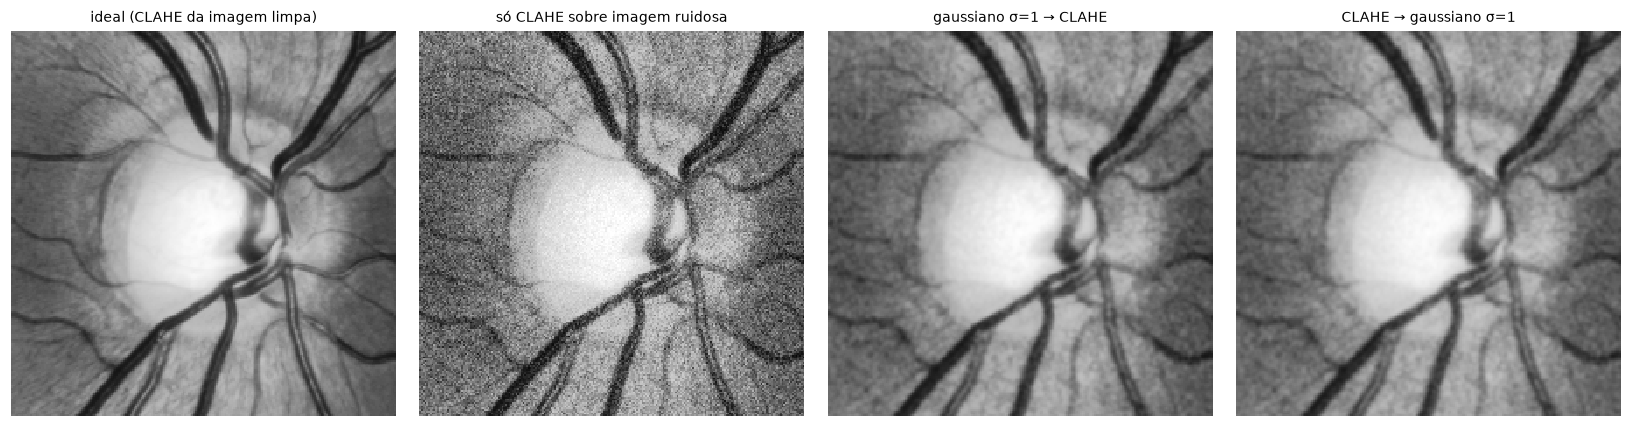

In [16]:
fig, axs = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, (t, im) in zip(axs, [("ideal (CLAHE da imagem limpa)", alvo), ("só CLAHE sobre imagem ruidosa", receitas["só CLAHE"]),
                             ("gaussiano σ=1 → CLAHE", receitas["gaussiano σ=1 → CLAHE"]), ("CLAHE → gaussiano σ=1", receitas["CLAHE → gaussiano σ=1"])]):
    ax.imshow(im[zoom], cmap="gray", vmin=0, vmax=255); ax.set_title(t, fontsize=9); ax.axis("off")
fig.tight_layout(); plt.show()

Três lições dos números acima:

1. **Filtrar é indispensável:** o CLAHE direto sobre a imagem ruidosa é o pior caso (SSIM ≈ 0,26 contra o ideal) — o ruído foi amplificado.
2. **Filtrar *antes*** leva a resultados mais próximos do ideal (PSNR maior, em todos os filtros): o ruído ainda é pequeno e não foi esticado pelo CLAHE.
3. Filtrar **depois** preserva mais contraste de vasos (*d* maior: o borrão só atua após o realce), mas o ruído já amplificado só é atenuado, não removido. As duas ordens são bem melhores do que não filtrar.

**Receita do pipeline:** *(1) preencher fora do FOV → (2) suavização leve (mediana 3 ou gaussiano σ ≈ 1) → (3) CLAHE em L (clip ≈ 2, 8×8) → (4) recolocar a moldura preta.*
Quando o desempenho dos vasos for crítico, teste a ordem inversa com a métrica da tarefa (exercício 3).

## 8. O efeito em cada condição e fonte

Aplicamos a receita (CLAHE em **L**, clip 2, 8×8) a exemplos das quatro condições e três câmeras:

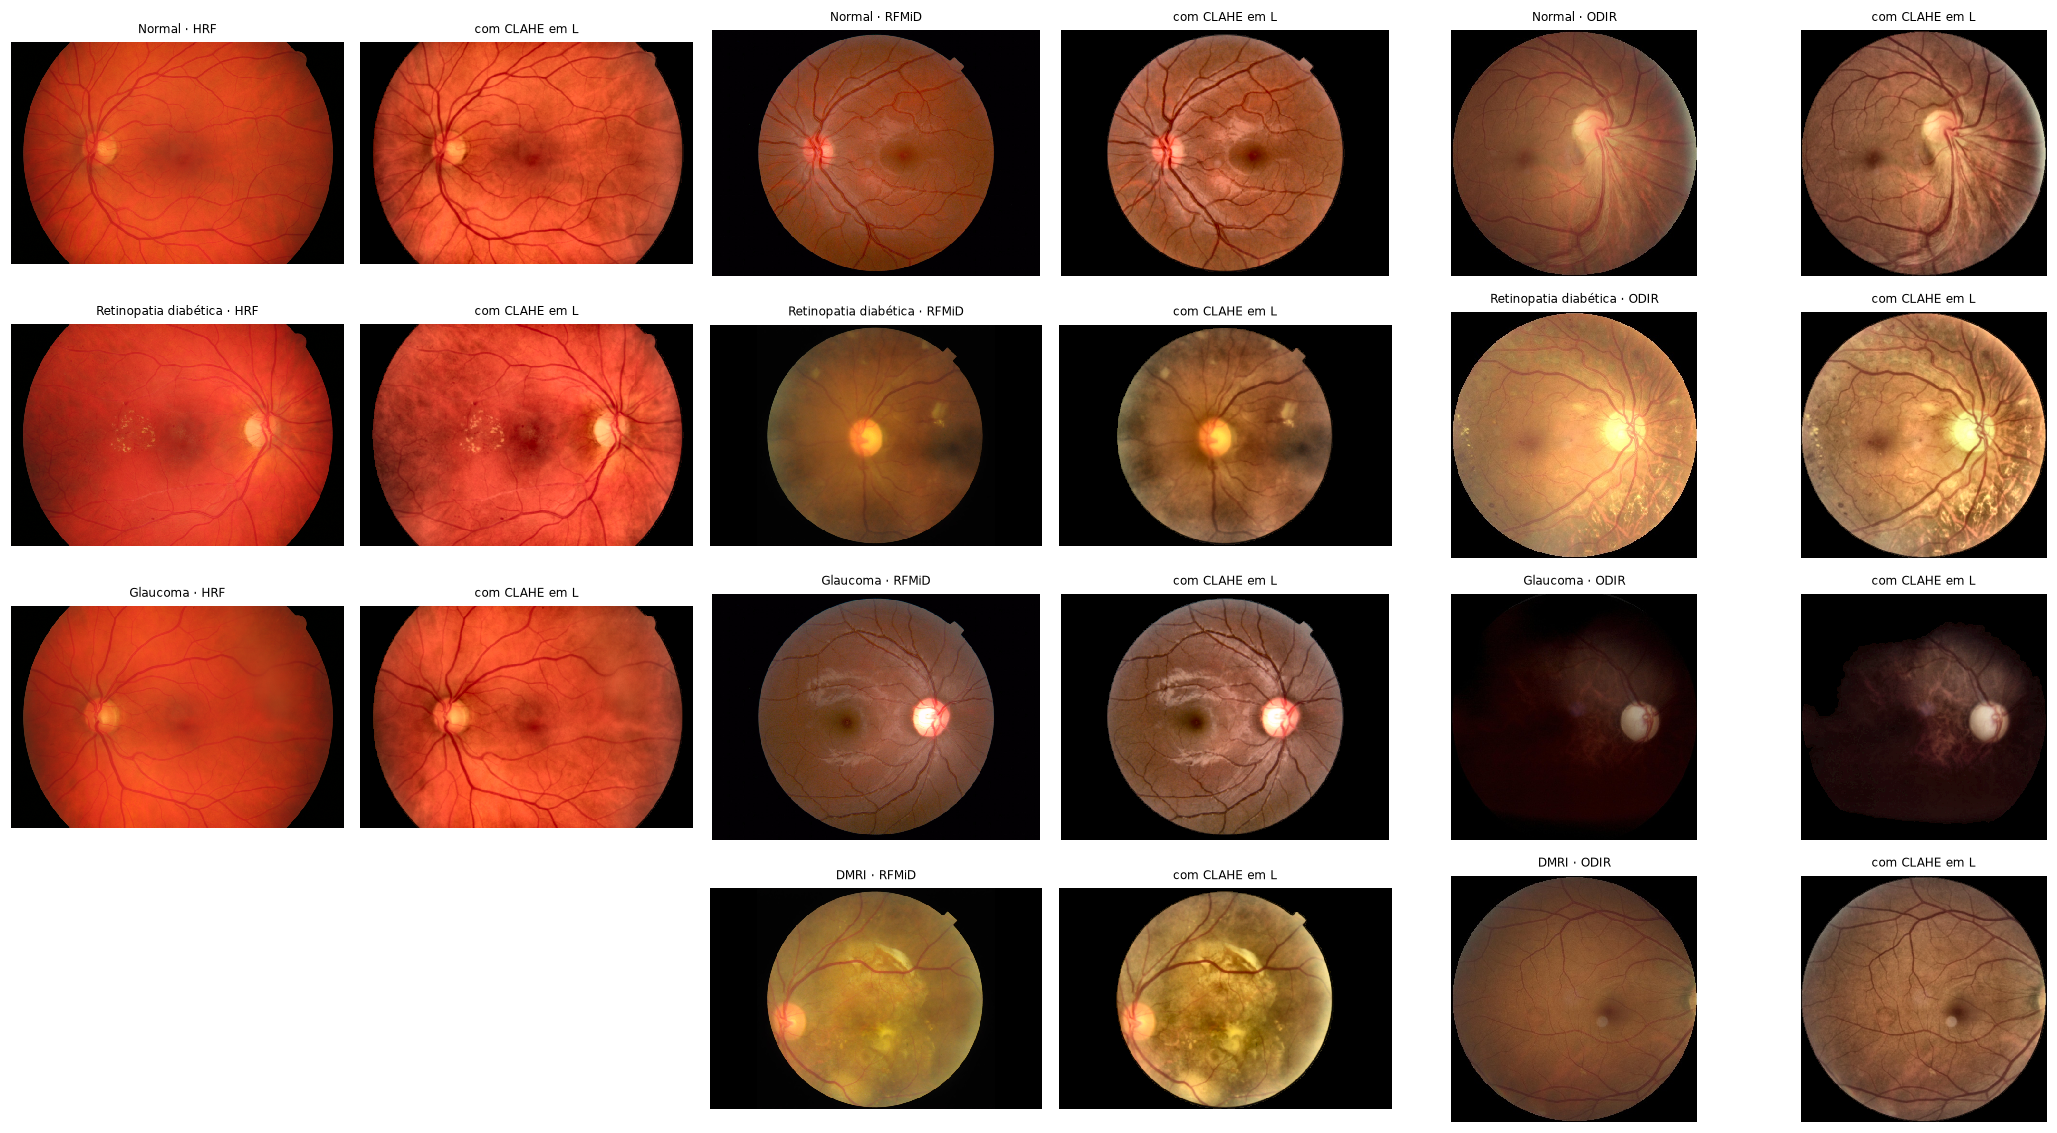

In [17]:
def realcar(rgb_, clip=2.0, grade=(8, 8)):
    f_ = P.mascara_fov(rgb_)
    prep = np.stack([P.preencher_fora_do_fov(rgb_[..., c], f_) for c in range(3)], -1)
    out = P.clahe_lab(cv2.GaussianBlur(prep, (0, 0), 0.8), clip, grade)
    out[~f_] = 0
    return out

fontes = ["HRF", "RFMiD", "ODIR"]
fig, axs = plt.subplots(len(dados.CONDICOES), 2 * len(fontes), figsize=(3.2 * 2 * len(fontes), 2.6 * len(dados.CONDICOES)))
for i, c in enumerate(dados.CONDICOES):
    for j, f in enumerate(fontes):
        a0, a1 = axs[i, 2 * j], axs[i, 2 * j + 1]; a0.axis("off"); a1.axis("off")
        s = dados.selecionar(c, f, n=1, seed=5)
        if len(s):
            im = dados.reduzir(dados.carregar_rgb(s.iloc[0].arquivo), 700)
            a0.imshow(im); a0.set_title(f"{dados.NOMES_CONDICAO[c]} · {f}", fontsize=8)
            a1.imshow(realcar(im)); a1.set_title("com CLAHE em L", fontsize=8)
fig.tight_layout(); V.salvar_figura(fig, "03_clahe_condicoes"); plt.show()

Observe que o realce **aproxima o aspecto** de câmeras diferentes (menos diferença de brilho/tom entre HRF, RFMiD e ODIR) e destaca drusas (DMRI), exsudatos (RD) e a escavação do disco.
Isso ajuda modelos a generalizar entre câmeras — mas também pode **criar** aparência de lesão em regiões de baixo contraste: nunca interprete a imagem realçada como se fosse a captura original.

## Exercícios propostos

1. **AHE sem limite.** Implemente a equalização adaptativa por blocos *sem* o limite de contraste (`clipLimit` muito alto, p. ex. 255) e mostre a amplificação de ruído em áreas planas (fundo da retina).
2. **Grade relativa ao tamanho.** Em vez de 8×8 fixos, escolha `tileGridSize` para que cada bloco tenha ~ 64 px de lado. O melhor par (clip, grade) muda quando a imagem tem 1168 px e quando tem 512 px?
3. **Otimize pela tarefa.** Repita o grid da seção 4 usando como métrica o **Dice** da segmentação de vasos do notebook 04 (função `P.segmentar_vasos`) em vez do *d* de Cohen. O ótimo coincide?
4. **Filtro × câmera.** Adicione ruído gaussiano σ = 15 a uma imagem do ODIR (512 px) e outra do HRF (1168 px). O melhor filtro é o mesmo? (Dica: a escala do ruído e das estruturas muda com a resolução.)
5. **Ben Graham × CLAHE.** Compare, nos mesmos 9 casos da seção 4, o ganho de *d* dos vasos do realce de Ben Graham com o do CLAHE em L. Qual altera menos a cromaticidade?
6. **Sensor real.** Com as capturas do Lab Maker (Módulo 02, sessão presencial), estime o σ do ruído com `qualidade.estimar_ruido` em função do ganho analógico e proponha o filtro de pré-processamento.